# Airshed sensor forecasting with machine learning

Run the cells from top to bottom. This notebook downloads up to 5,000 real, read-only `sensor_logs` records from Firebase and trains a small 1D CNN for PM2.5, humidity, temperature, and the MQ-7 raw ADC signal at 30-minute and 2-hour horizons.

It does not create fake readings, interpolate gaps, or change the live website. Regression accuracy here means the percentage of predictions within PM2.5 ±5 µg/m³, humidity ±5 percentage points, temperature ±1°C, and MQ raw ADC ±17 counts. The MQ tolerance is an evaluation threshold based on 5% of the observed 10–350 raw-count range in the current history. The CNN is selected only when its validation accuracy is at least 3 percentage points above the latest-reading baseline; otherwise the notebook uses that baseline.

The firmware currently uploads temperature and humidity from Open-Meteo current conditions. The `co` field stores the MQ-7 sensor response as raw ADC counts, and the notebook forecasts changes in this sensor-response signal.

The CNN uses 5-minute sensor windows from the previous hour. It allows up to 150 epochs and stops early if validation loss fails to improve for 15 epochs. If imports fail in your kernel, run `%pip install requests pandas numpy matplotlib scikit-learn torch` once, then restart the kernel.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from IPython.display import display
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.preprocessing import StandardScaler
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

FIREBASE_URL = "https://airshed-4ec87-default-rtdb.asia-southeast1.firebasedatabase.app"
MAX_READINGS = 5000
TARGETS = ["pm25", "hum", "temp", "co"]
VALID_RANGES = {"pm25": (0, 1000), "hum": (0, 100), "temp": (-40, 85), "co": (0, 1023)}
HORIZONS_MINUTES = [30, 120]
LAGS_MINUTES = list(range(0, 61, 5))
TIME_TOLERANCE = pd.Timedelta(minutes=3)
MIN_TRAIN_ROWS = 50
MIN_VALIDATION_ROWS = 10
MIN_TEST_ROWS = 10

print("Dependencies loaded.")

Dependencies loaded.


In [2]:
params = {"orderBy": json.dumps("timestamp"), "limitToLast": MAX_READINGS}
response = requests.get(f"{FIREBASE_URL}/sensor_logs.json", params=params, timeout=30)
response.raise_for_status()
payload = response.json()

if not isinstance(payload, dict) or not payload:
    raise RuntimeError("Firebase returned no sensor logs. Check the read-only database rules and try again.")

data = pd.DataFrame.from_dict(payload, orient="index").reset_index(drop=True)
required = {"source", "timestamp", *TARGETS}
missing = required.difference(data.columns)
if missing:
    raise ValueError(f"Sensor logs are missing required fields: {sorted(missing)}")

data = data.loc[data["source"].eq("device"), ["timestamp", *TARGETS]].copy()
data["timestamp"] = pd.to_datetime(data["timestamp"], utc=True, errors="coerce")
for column in TARGETS:
    data[column] = pd.to_numeric(data[column], errors="coerce")
    low, high = VALID_RANGES[column]
    data.loc[~data[column].between(low, high), column] = np.nan

data = (
    data.dropna(subset=["timestamp", *TARGETS])
    .sort_values("timestamp")
    .drop_duplicates("timestamp", keep="last")
    .reset_index(drop=True)
)

if len(data) < 100:
    raise RuntimeError(f"Only {len(data)} valid device readings were found. More real history is needed before training.")

print(f"Loaded {len(data):,} valid device readings.")
print(f"Range: {data['timestamp'].min()} to {data['timestamp'].max()}")
display(data.tail())

Loaded 4,019 valid device readings.
Range: 2026-11-17 10:14:43+00:00 to 2026-11-25 05:30:42+00:00


,timestamp,pm25,hum,temp,co
4014,2026-11-25 05:26:11+00:00,0.0,83.0,27.6,154.0
4015,2026-11-25 05:27:18+00:00,0.0,83.0,27.6,208.0
4016,2026-11-25 05:28:26+00:00,0.0,83.0,27.6,170.0
4017,2026-11-25 05:29:33+00:00,0.0,83.0,27.6,213.0
4018,2026-11-25 05:30:42+00:00,0.0,82.0,27.9,181.0


In [3]:
def build_features(readings):
    features = pd.DataFrame({"anchor_time": readings["timestamp"]})
    for lag in LAGS_MINUTES:
        left = pd.DataFrame({"anchor_time": readings["timestamp"]})
        left["lookup_time"] = left["anchor_time"] - pd.Timedelta(minutes=lag)
        renamed = {"timestamp": "reading_time"}
        renamed.update({name: f"{name}_lag_{lag}" for name in TARGETS})
        right = readings[["timestamp", *TARGETS]].rename(columns=renamed)
        joined = pd.merge_asof(
            left.sort_values("lookup_time"),
            right.sort_values("reading_time"),
            left_on="lookup_time",
            right_on="reading_time",
            direction="backward",
            tolerance=TIME_TOLERANCE,
        )
        lag_columns = [f"{name}_lag_{lag}" for name in TARGETS]
        features = features.merge(joined[["anchor_time", *lag_columns]], on="anchor_time", how="left")

    local_time = features["anchor_time"].dt.tz_convert("Asia/Manila")
    minute_of_day = local_time.dt.hour * 60 + local_time.dt.minute
    features["time_sin"] = np.sin(2 * np.pi * minute_of_day / 1440)
    features["time_cos"] = np.cos(2 * np.pi * minute_of_day / 1440)
    features["weekday_sin"] = np.sin(2 * np.pi * local_time.dt.day_of_week / 7)
    features["weekday_cos"] = np.cos(2 * np.pi * local_time.dt.day_of_week / 7)

    feature_columns = [column for column in features.columns if column != "anchor_time"]
    features = features.dropna(subset=feature_columns).sort_values("anchor_time").reset_index(drop=True)
    return features, feature_columns


features, FEATURE_COLUMNS = build_features(data)
print(f"Usable feature rows after real-time lag matching: {len(features):,}")
if len(features) < MIN_TRAIN_ROWS + MIN_VALIDATION_ROWS + MIN_TEST_ROWS:
    raise RuntimeError("Not enough rows have complete real readings at all lag times. Collect more device data.")

Usable feature rows after real-time lag matching: 2,367


Latest sensor reading: 2026-11-25 13:30:42+08:00 Manila time
Fresh enough for a current estimate: False
Complete lag features for that reading: False

30-minute forecast — train: 1515, validation: 307, test: 327


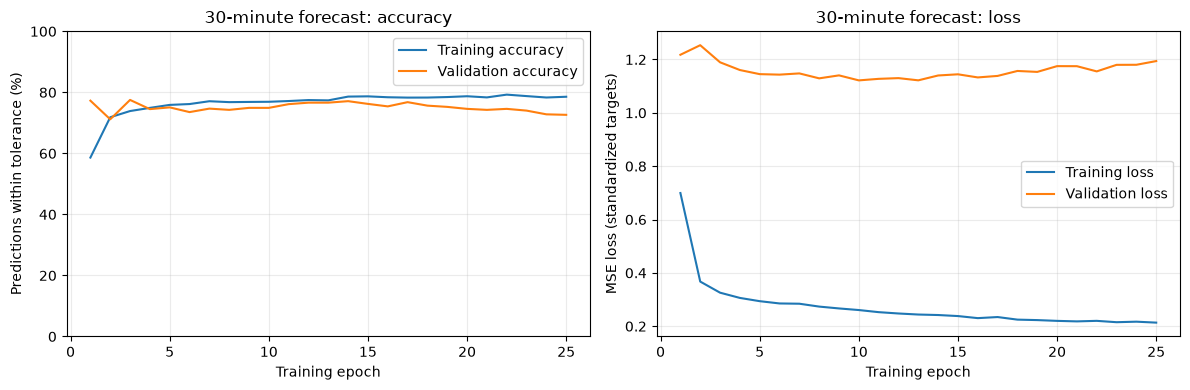

Completed 25 epochs; selected best checkpoint at epoch 10 using validation loss.

120-minute forecast — train: 1343, validation: 198, test: 295


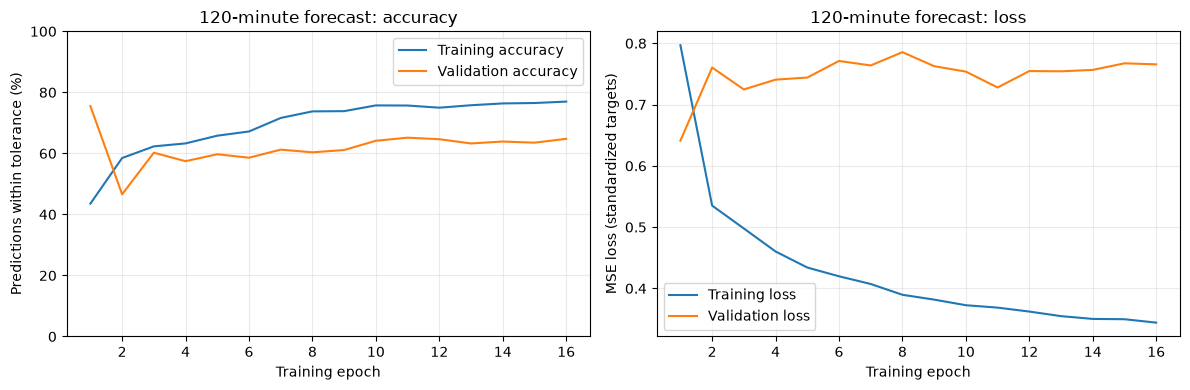

Completed 16 epochs; selected best checkpoint at epoch 1 using validation loss.


,horizon_minutes,target,validation_CNN_MAE,validation_latest_reading_MAE,validation_CNN_accuracy_pct,validation_baseline_accuracy_pct,validation_MAE_improvement_pct,validation_accuracy_improvement_pp,test_CNN_MAE,test_latest_reading_MAE,test_CNN_accuracy_pct,test_baseline_accuracy_pct,selected_method
0,30,pm25,6.78,7.63,64.50,71.01,11.12,-6.51,11.27,10.55,61.77,73.70,Latest-reading baseline
1,30,hum,2.12,1.21,99.35,99.67,-75.14,-0.33,2.53,1.55,92.66,99.39,Latest-reading baseline
2,30,temp,0.26,0.15,100.00,100.00,-69.51,0.00,0.26,0.31,100.00,100.00,Latest-reading baseline
3,30,co,24.02,27.16,35.83,43.00,11.55,-7.17,27.03,30.03,40.06,39.45,Latest-reading baseline
4,120,pm25,4.98,6.20,75.76,78.28,19.74,-2.53,3.69,5.76,89.49,67.46,Latest-reading baseline
5,120,hum,2.49,4.94,100.00,57.58,49.73,42.42,6.80,6.40,16.61,46.78,CNN
6,120,temp,0.57,0.67,100.00,83.84,14.71,16.16,1.24,0.96,23.73,55.25,CNN
7,120,co,23.36,29.69,26.26,40.91,21.30,-14.65,23.40,28.60,37.97,41.02,Latest-reading baseline



Holdout PM2.5 AQI-category accuracy:


,horizon_minutes,method,overall_category_accuracy_pct,balanced_category_accuracy_pct
0,30,CNN,86.85,33.33
1,30,Latest-reading baseline,76.76,33.88
2,120,CNN,91.53,50.00
3,120,Latest-reading baseline,77.63,47.85


Per-category recall and actual sample count; categories with no examples show NaN:


,horizon_minutes,method,category,actual_count,correctly_classified_pct
0,30,CNN,Good,284,100.00
1,30,CNN,Moderate,39,0.00
2,30,CNN,Unhealthy,0,NaN
3,30,CNN,Hazardous,4,0.00
4,30,Latest-reading baseline,Good,284,86.27
5,30,Latest-reading baseline,Moderate,39,15.38
6,30,Latest-reading baseline,Unhealthy,0,NaN
7,30,Latest-reading baseline,Hazardous,4,0.00
8,120,CNN,Good,270,100.00
9,120,CNN,Moderate,25,0.00


No current forecast: the newest complete reading is older than three minutes or there was not enough training data.


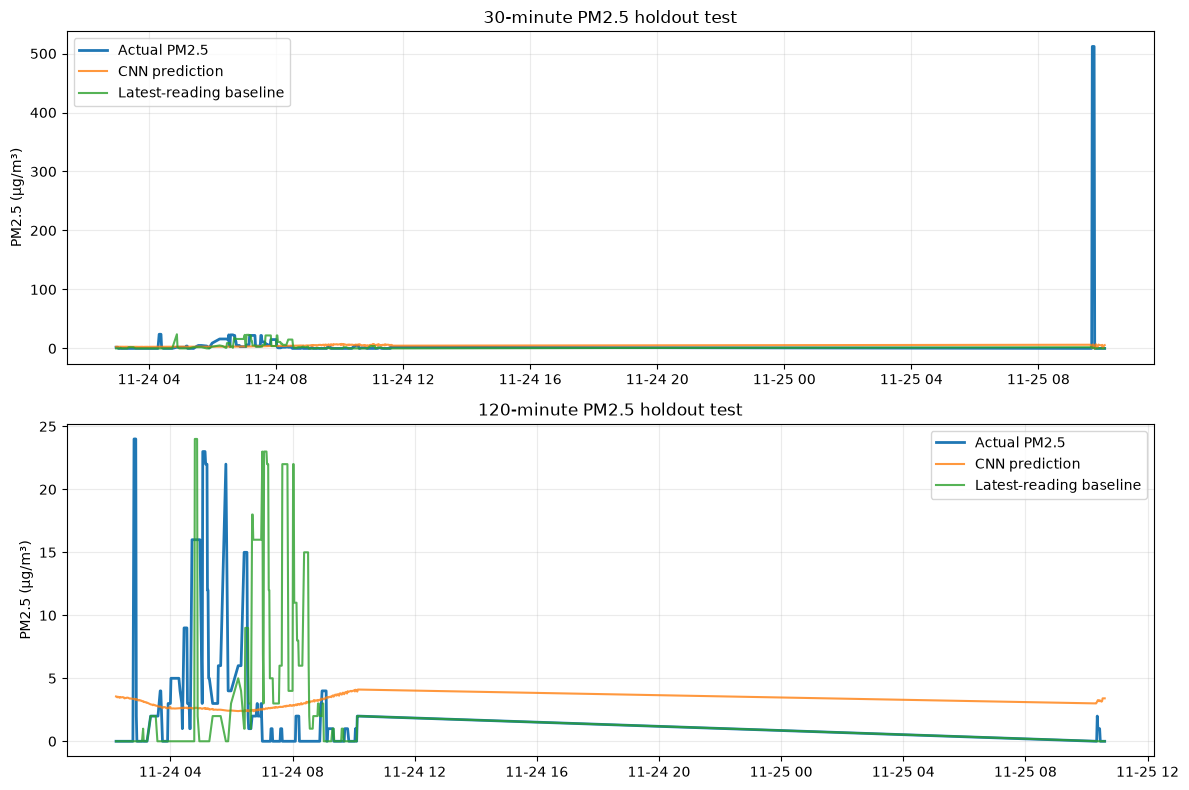

In [4]:
def make_supervised(feature_rows, readings, horizon_minutes):
    anchors = feature_rows.copy()
    anchors["target_time"] = anchors["anchor_time"] + pd.Timedelta(minutes=horizon_minutes)
    rename_targets = {"timestamp": "future_reading_time"}
    rename_targets.update({name: f"y_{name}" for name in TARGETS})
    future = readings[["timestamp", *TARGETS]].rename(columns=rename_targets)
    joined = pd.merge_asof(
        anchors.sort_values("target_time"),
        future.sort_values("future_reading_time"),
        left_on="target_time",
        right_on="future_reading_time",
        direction="forward",
        tolerance=TIME_TOLERANCE,
    )
    return joined.dropna(subset=[f"y_{name}" for name in TARGETS]).sort_values("anchor_time").reset_index(drop=True)


def chronological_split(rows):
    rows = rows.sort_values("anchor_time").reset_index(drop=True)
    first_cut = rows["anchor_time"].iloc[int(len(rows) * 0.70)]
    second_cut = rows["anchor_time"].iloc[int(len(rows) * 0.85)]
    train = rows.loc[rows["target_time"] < first_cut].copy()
    validation = rows.loc[(rows["anchor_time"] >= first_cut) & (rows["target_time"] < second_cut)].copy()
    test = rows.loc[rows["anchor_time"] >= second_cut].copy()
    return train, validation, test


TIME_FEATURE_COLUMNS = ["time_sin", "time_cos", "weekday_sin", "weekday_cos"]
SEQUENCE_COLUMNS = [f"{name}_lag_{lag}" for lag in LAGS_MINUTES for name in TARGETS]


class SensorCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.convolutions = nn.Sequential(
            nn.Conv1d(len(TARGETS), 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv1d(32, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2),
            nn.Conv1d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.AdaptiveAvgPool1d(1),
        )
        self.regressor = nn.Sequential(
            nn.Linear(64 + len(TIME_FEATURE_COLUMNS), 32),
            nn.ReLU(),
            nn.Dropout(p=0.1),
            nn.Linear(32, len(TARGETS)),
        )

    def forward(self, sequence, time_features):
        encoded = self.convolutions(sequence).squeeze(-1)
        return self.regressor(torch.cat((encoded, time_features), dim=1))


def transform_cnn_inputs(rows, sequence_scaler, time_scaler):
    sequence = rows[SEQUENCE_COLUMNS].to_numpy().reshape(len(rows), len(LAGS_MINUTES), len(TARGETS))
    sequence = sequence_scaler.transform(sequence.reshape(-1, len(TARGETS)))
    sequence = sequence.reshape(len(rows), len(LAGS_MINUTES), len(TARGETS)).transpose(0, 2, 1)
    time_features = time_scaler.transform(rows[TIME_FEATURE_COLUMNS])
    return (
        torch.tensor(sequence, dtype=torch.float32),
        torch.tensor(time_features, dtype=torch.float32),
    )


def predict_cnn(model, rows, sequence_scaler, time_scaler, y_scaler):
    sequence, time_features = transform_cnn_inputs(rows, sequence_scaler, time_scaler)
    model.eval()
    with torch.no_grad():
        standardized = model(sequence, time_features).numpy()
    return y_scaler.inverse_transform(standardized)


ACCURACY_TOLERANCES = {"pm25": 5.0, "hum": 5.0, "temp": 1.0, "co": 17.0}


def tolerance_accuracy(actual, prediction):
    tolerances = np.array([ACCURACY_TOLERANCES[target] for target in TARGETS])
    return np.mean(np.abs(actual - prediction) <= tolerances) * 100


AQI_CATEGORIES = ["Good", "Moderate", "Unhealthy", "Hazardous"]


def classify_pm25(values):
    values = np.asarray(values, dtype=float)
    return np.select(
        [values <= 12, values <= 35, values <= 150],
        AQI_CATEGORIES[:3],
        default=AQI_CATEGORIES[3],
    )


def fit_cnn(train, validation):
    sequence_scaler = StandardScaler().fit(
        train[SEQUENCE_COLUMNS].to_numpy().reshape(-1, len(TARGETS))
    )
    time_scaler = StandardScaler().fit(train[TIME_FEATURE_COLUMNS])
    y_columns = [f"y_{name}" for name in TARGETS]
    y_scaler = StandardScaler().fit(train[y_columns])
    x_train_sequence, x_train_time = transform_cnn_inputs(train, sequence_scaler, time_scaler)
    x_validation_sequence, x_validation_time = transform_cnn_inputs(validation, sequence_scaler, time_scaler)
    y_train = torch.tensor(y_scaler.transform(train[y_columns]), dtype=torch.float32)
    y_validation = torch.tensor(y_scaler.transform(validation[y_columns]), dtype=torch.float32)

    torch.manual_seed(42)
    model = SensorCNN()
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001, weight_decay=0.001)
    loss_function = nn.MSELoss()
    loader = DataLoader(
        TensorDataset(x_train_sequence, x_train_time, y_train),
        batch_size=64,
        shuffle=True,
    )
    history = {"train_loss": [], "validation_loss": [], "train_accuracy": [], "validation_accuracy": []}
    best_state = None
    best_validation_loss = np.inf
    best_epoch = 0
    patience = 15
    wait = 0

    for epoch in range(1, 151):
        model.train()
        for batch_sequence, batch_time, batch_y in loader:
            optimizer.zero_grad(set_to_none=True)
            loss = loss_function(model(batch_sequence, batch_time), batch_y)
            loss.backward()
            optimizer.step()

        model.eval()
        with torch.no_grad():
            train_prediction = model(x_train_sequence, x_train_time)
            validation_prediction = model(x_validation_sequence, x_validation_time)
            train_loss = loss_function(train_prediction, y_train).item()
            validation_loss = loss_function(validation_prediction, y_validation).item()
            train_prediction_values = y_scaler.inverse_transform(train_prediction.numpy())
            validation_prediction_values = y_scaler.inverse_transform(validation_prediction.numpy())
            train_accuracy = tolerance_accuracy(train[y_columns].to_numpy(), train_prediction_values)
            validation_accuracy = tolerance_accuracy(validation[y_columns].to_numpy(), validation_prediction_values)

        history["train_loss"].append(train_loss)
        history["validation_loss"].append(validation_loss)
        history["train_accuracy"].append(train_accuracy)
        history["validation_accuracy"].append(validation_accuracy)

        if validation_loss < best_validation_loss:
            best_validation_loss = validation_loss
            best_state = {name: value.detach().clone() for name, value in model.state_dict().items()}
            best_epoch = epoch
            wait = 0
        else:
            wait += 1
            if wait >= patience:
                break

    if best_state is None:
        raise RuntimeError("CNN training did not produce a valid checkpoint.")
    model.load_state_dict(best_state)
    return model, sequence_scaler, time_scaler, y_scaler, history, best_epoch


def plot_learning_curves(history, horizon_minutes):
    epochs = np.arange(1, len(history["train_loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(epochs, history["train_accuracy"], label="Training accuracy")
    axes[0].plot(epochs, history["validation_accuracy"], label="Validation accuracy")
    axes[0].set_title(f"{horizon_minutes}-minute forecast: accuracy")
    axes[0].set_xlabel("Training epoch")
    axes[0].set_ylabel("Predictions within tolerance (%)")
    axes[0].set_ylim(0, 100)
    axes[0].legend()
    axes[0].grid(alpha=0.25)
    axes[1].plot(epochs, history["train_loss"], label="Training loss")
    axes[1].plot(epochs, history["validation_loss"], label="Validation loss")
    axes[1].set_title(f"{horizon_minutes}-minute forecast: loss")
    axes[1].set_xlabel("Training epoch")
    axes[1].set_ylabel("MSE loss (standardized targets)")
    axes[1].legend()
    axes[1].grid(alpha=0.25)
    plt.tight_layout()
    plt.show()


score_rows = []
forecast_rows = []
test_plot_rows = {}
aqi_accuracy_rows = []
aqi_category_rows = []
latest_reading_time = data["timestamp"].iloc[-1]
latest_feature_time = features["anchor_time"].iloc[-1]
reading_age = pd.Timestamp.now(tz="UTC") - latest_reading_time
latest_reading_is_fresh = reading_age <= pd.Timedelta(minutes=3)
latest_features_are_current = latest_feature_time == latest_reading_time
print(f"Latest sensor reading: {latest_reading_time.tz_convert('Asia/Manila')} Manila time")
print(f"Fresh enough for a current estimate: {latest_reading_is_fresh}")
print(f"Complete lag features for that reading: {latest_features_are_current}")

for horizon in HORIZONS_MINUTES:
    supervised = make_supervised(features, data, horizon)
    if len(supervised) < MIN_TRAIN_ROWS + MIN_VALIDATION_ROWS + MIN_TEST_ROWS:
        print(f"Skipped: only {len(supervised)} real horizon-matched rows are available.")
        continue
    train, validation, test = chronological_split(supervised)
    print(f"\n{horizon}-minute forecast — train: {len(train)}, validation: {len(validation)}, test: {len(test)}")

    if len(train) < MIN_TRAIN_ROWS or len(validation) < MIN_VALIDATION_ROWS or len(test) < MIN_TEST_ROWS:
        print("Skipped: insufficient real, time-matched readings for all three splits.")
        continue

    model, sequence_scaler, time_scaler, y_scaler, history, best_epoch = fit_cnn(train, validation)
    plot_learning_curves(history, horizon)
    print(f"Completed {len(history['train_loss'])} epochs; selected best checkpoint at epoch {best_epoch} using validation loss.")

    y_columns = [f"y_{name}" for name in TARGETS]
    validation_prediction = predict_cnn(model, validation, sequence_scaler, time_scaler, y_scaler)
    test_prediction = predict_cnn(model, test, sequence_scaler, time_scaler, y_scaler)
    validation_actual = validation[y_columns].to_numpy()
    test_actual = test[y_columns].to_numpy()
    validation_baseline = validation[[f"{name}_lag_0" for name in TARGETS]].to_numpy()
    test_baseline = test[[f"{name}_lag_0" for name in TARGETS]].to_numpy()

    for column, target in enumerate(TARGETS):
        validation_cnn_mae = mean_absolute_error(validation_actual[:, column], validation_prediction[:, column])
        validation_baseline_mae = mean_absolute_error(validation_actual[:, column], validation_baseline[:, column])
        validation_cnn_accuracy = np.mean(np.abs(validation_actual[:, column] - validation_prediction[:, column]) <= ACCURACY_TOLERANCES[target]) * 100
        validation_baseline_accuracy = np.mean(np.abs(validation_actual[:, column] - validation_baseline[:, column]) <= ACCURACY_TOLERANCES[target]) * 100
        mae_improvement_pct = (1 - validation_cnn_mae / validation_baseline_mae) * 100 if validation_baseline_mae > 0 else 0.0
        accuracy_improvement_pp = validation_cnn_accuracy - validation_baseline_accuracy
        use_cnn = accuracy_improvement_pp >= 3.0
        test_cnn_mae = mean_absolute_error(test_actual[:, column], test_prediction[:, column])
        test_baseline_mae = mean_absolute_error(test_actual[:, column], test_baseline[:, column])
        test_cnn_accuracy = np.mean(np.abs(test_actual[:, column] - test_prediction[:, column]) <= ACCURACY_TOLERANCES[target]) * 100
        test_baseline_accuracy = np.mean(np.abs(test_actual[:, column] - test_baseline[:, column]) <= ACCURACY_TOLERANCES[target]) * 100
        score_rows.append({
            "horizon_minutes": horizon,
            "target": target,
            "validation_CNN_MAE": validation_cnn_mae,
            "validation_latest_reading_MAE": validation_baseline_mae,
            "validation_CNN_accuracy_pct": validation_cnn_accuracy,
            "validation_baseline_accuracy_pct": validation_baseline_accuracy,
            "validation_MAE_improvement_pct": mae_improvement_pct,
            "validation_accuracy_improvement_pp": accuracy_improvement_pp,
            "test_CNN_MAE": test_cnn_mae,
            "test_latest_reading_MAE": test_baseline_mae,
            "test_CNN_accuracy_pct": test_cnn_accuracy,
            "test_baseline_accuracy_pct": test_baseline_accuracy,
            "selected_method": "CNN" if use_cnn else "Latest-reading baseline",
        })

        if latest_reading_is_fresh:
            if use_cnn and latest_features_are_current:
                current_features = features.iloc[[-1]]
                cnn_value = predict_cnn(model, current_features, sequence_scaler, time_scaler, y_scaler)[0, column]
                low, high = VALID_RANGES[target]
                forecast_value = float(np.clip(cnn_value, low, high))
                current_method = "CNN"
            else:
                forecast_value = float(data.iloc[-1][target])
                current_method = "Latest-reading baseline"
            forecast_rows.append({
                "horizon_minutes": horizon,
                "target": target,
                "estimate": forecast_value,
                "method": current_method,
                "validation_accuracy_improvement_pp": accuracy_improvement_pp,
            })

    actual_categories = classify_pm25(test_actual[:, 0])
    for method, pm25_prediction in [
        ("CNN", test_prediction[:, 0]),
        ("Latest-reading baseline", test_baseline[:, 0]),
    ]:
        predicted_categories = classify_pm25(np.clip(pm25_prediction, 0, 1000))
        category_recalls = []
        for category in AQI_CATEGORIES:
            actual_category_rows = actual_categories == category
            support = int(actual_category_rows.sum())
            correctly_classified_pct = (
                np.mean(predicted_categories[actual_category_rows] == category) * 100
                if support else np.nan
            )
            if support:
                category_recalls.append(correctly_classified_pct)
            aqi_category_rows.append({
                "horizon_minutes": horizon,
                "method": method,
                "category": category,
                "actual_count": support,
                "correctly_classified_pct": correctly_classified_pct,
            })
        aqi_accuracy_rows.append({
            "horizon_minutes": horizon,
            "method": method,
            "overall_category_accuracy_pct": np.mean(actual_categories == predicted_categories) * 100,
            "balanced_category_accuracy_pct": np.mean(category_recalls) if category_recalls else np.nan,
        })

    test_plot_rows[horizon] = (test["anchor_time"], test_actual[:, 0], test_prediction[:, 0], test_baseline[:, 0])

if score_rows:
    scores = pd.DataFrame(score_rows)
    display(scores.round(2))
else:
    print("No model was trained. Collect more real sensor readings and run the notebook again.")

if aqi_accuracy_rows:
    print("\nHoldout PM2.5 AQI-category accuracy:")
    display(pd.DataFrame(aqi_accuracy_rows).round(2))
    print("Per-category recall and actual sample count; categories with no examples show NaN:")
    display(pd.DataFrame(aqi_category_rows).round(2))

if forecast_rows:
    forecasts = pd.DataFrame(forecast_rows)
    display(forecasts.round(2))
else:
    print("No current forecast: the newest complete reading is older than three minutes or there was not enough training data.")

if test_plot_rows:
    fig, axes = plt.subplots(len(test_plot_rows), 1, figsize=(12, 4 * len(test_plot_rows)), squeeze=False)
    for axis, (horizon, series) in zip(axes[:, 0], test_plot_rows.items()):
        times, actual, cnn_prediction, baseline_prediction = series
        axis.plot(times.dt.tz_convert("Asia/Manila"), actual, label="Actual PM2.5", linewidth=2)
        axis.plot(times.dt.tz_convert("Asia/Manila"), cnn_prediction, label="CNN prediction", alpha=0.8)
        axis.plot(times.dt.tz_convert("Asia/Manila"), baseline_prediction, label="Latest-reading baseline", alpha=0.8)
        axis.set_title(f"{horizon}-minute PM2.5 holdout test")
        axis.set_ylabel("PM2.5 (µg/m³)")
        axis.legend()
        axis.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()

## How to read the output

- Accuracy is the percentage of predictions within PM2.5 ±5 µg/m³, humidity ±5 percentage points, and temperature ±1°C. The accuracy curve averages those checks across all three targets.
- A separate holdout report shows overall and balanced PM2.5 AQI-category accuracy using the website's Good (≤12), Moderate (>12–35), Unhealthy (>35–150), and Hazardous (>150–1000) breakpoints. Per-category recall includes the actual sample count; a category with no examples has no score.
- The score table includes tolerance accuracy and MAE. Validation selects the CNN only when tolerance accuracy is at least 3 percentage points higher; the untouched test set reports performance without influencing selection.
- If the latest-reading baseline is selected, the estimate is still based on a real recent reading, and the table labels it as a baseline rather than an ML prediction.
- This notebook is for experimentation. The website will not use these model results until a separate, reviewed deployment change is made.